# 12 Advanced models (work in progress)

This notebook is a start, not a result. We try three more models on a small subset of 30 products, to see
whether they are worth a proper run later: XGBoost on the same features as LightGBM, Prophet, and a small GRU (a
recurrent neural network). They use the same backtest and scores as everything else, so the numbers can be compared
with notebook 10, but 30 products is too few to draw conclusions from, and none of the settings here have been tuned.
Nothing from this notebook goes into the findings or onto the dashboard's main pages.

## Load

In [1]:
import os, sys, time, logging, warnings
sys.path.append("../src")
warnings.filterwarnings("ignore")
for name in ["cmdstanpy", "prophet"]:                # Prophet logs every fit; keep the output readable
    logging.getLogger(name).disabled = True

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import ROOT, RAW, INTERIM, PROCESSED, TABLES, FIGS, ORIGINS, EVAL_ORIGINS, HORIZON, FIT_DAYS, SEED, FIG_STYLE, NAMES
from break_detection import weekly_ca_prices
from forecasting import build_lgb_panel, LGB_FEATURES
from evaluation import METRICS, score

RERUN = False
plt.rcParams.update(FIG_STYLE)
written = []

long_df = pd.concat([pd.read_csv(INTERIM / f"{c}_candidates.csv", parse_dates=["date"])
                     for c in ["foods", "hobbies", "household"]], ignore_index=True)
long_df = long_df.sort_values(["item_id", "date"]).reset_index(drop=True)
sample = pd.read_csv(TABLES / "classical_sample_items.csv")
subset = sample.groupby("category")["item_id"].apply(lambda s: list(s[:10])).sum()     # first 10 per category
err = pd.read_csv(PROCESSED / "backtest_errors.csv", parse_dates=["origin"])
scales = err[["item_id", "origin", "mase_scale"]].drop_duplicates()
print(len(subset), "products:", subset[:3], "...")

30 products: ['FOODS_1_043', 'FOODS_1_085', 'FOODS_1_137'] ...


## XGBoost

The same 17 features as LightGBM, all sales features lagged at least 28 days, one model for all 726 products per
origin, trained on rows up to the origin. Tweedie loss, 300 rounds, learning rate 0.05, depth 6. We only score the 30
products. Product and department codes go in as plain numbers, which trees can still split on; LightGBM treats them
as categories, so this is one difference we have not tested.

In [2]:
path = PROCESSED / "advanced_xgboost_forecasts.parquet"
if RERUN or not path.exists():
    import xgboost as xgb
    cal = pd.read_csv(RAW / "calendar.csv", parse_dates=["date"])
    prices = pd.read_csv(RAW / "sell_prices.csv", dtype={"store_id": "category"})
    pw = weekly_ca_prices(prices, cal, long_df["item_id"].unique())
    del prices
    panel = build_lgb_panel(long_df, cal, pw)
    params = {"objective": "reg:tweedie", "tweedie_variance_power": 1.1, "eta": 0.05, "max_depth": 6,
              "subsample": 1.0, "colsample_bytree": 0.8, "lambda": 1.0, "seed": SEED, "nthread": 8}
    parts = []
    t0 = time.time()
    for o in ORIGINS:
        frame = panel[panel["date"] <= o + pd.Timedelta(days=HORIZON)]
        tr = frame[(frame["date"] <= o) & frame["rmean_56_l28"].notna()]
        te = frame[(frame["date"] > o) & frame["item_id"].isin(subset)]
        mdl = xgb.train(params, xgb.DMatrix(tr[LGB_FEATURES], label=tr["sales"]), num_boost_round=300)
        out = te[["item_id", "date"]].copy()
        out["forecast"] = np.maximum(mdl.predict(xgb.DMatrix(te[LGB_FEATURES])), 0)
        out["origin"], out["model"] = o, "xgboost"
        parts.append(out)
        print(f"origin {o.date()} done ({time.time() - t0:.0f}s)")
    pd.concat(parts, ignore_index=True).to_parquet(path, index=False)
xgb_fc = pd.read_parquet(path)
written.append(path)
print(len(xgb_fc), "rows")

5880 rows


## Prophet

Prophet fits a trend with weekly and yearly seasonality. We give it the same last 730 days as the classical models,
per product and origin, and clip forecasts at zero. Default settings otherwise.

In [3]:
path = PROCESSED / "advanced_prophet_forecasts.parquet"
if RERUN or not path.exists():
    from prophet import Prophet
    rows = []
    t0 = time.time()
    for item in subset:
        d = long_df[long_df["item_id"] == item]
        for o in ORIGINS:
            tr = d[d["date"] <= o].tail(FIT_DAYS).rename(columns={"date": "ds", "sales": "y"})[["ds", "y"]]
            mdl = Prophet(weekly_seasonality=True, yearly_seasonality=True, daily_seasonality=False)
            mdl.fit(tr)
            fut = pd.DataFrame({"ds": pd.date_range(o + pd.Timedelta(days=1), periods=HORIZON)})
            p = mdl.predict(fut)
            rows.append(pd.DataFrame({"item_id": item, "date": fut["ds"], "forecast": np.maximum(p["yhat"].to_numpy(), 0),
                                      "origin": o, "model": "prophet"}))
    pd.concat(rows, ignore_index=True).to_parquet(path, index=False)
    print(f"fitted in {(time.time() - t0) / 60:.1f} min")
prophet_fc = pd.read_parquet(path)
written.append(path)
print(len(prophet_fc), "rows")

5880 rows


## A small GRU

A prototype only. For each product we divide sales by its mean before the origin, so products of different size can
share one network. The input is the last 56 days, the output the next 28 days, all at once. One GRU layer with 32
units, trained for 15 passes over every 56-day window that ends at least 28 days before the origin, one network per
origin, on these 30 products only.

In [4]:
path = PROCESSED / "advanced_gru_forecasts.parquet"
if RERUN or not path.exists():
    import torch
    from torch import nn
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    IN = 56

    class Net(nn.Module):
        def __init__(self):
            super().__init__()
            self.gru = nn.GRU(1, 32, batch_first=True)
            self.out = nn.Linear(32, HORIZON)
        def forward(self, x):
            _, h = self.gru(x)
            return self.out(h[-1])

    series = {i: long_df[long_df["item_id"] == i].set_index("date")["sales"].astype(float) for i in subset}
    rows = []
    t0 = time.time()
    for o in ORIGINS:
        xs, ys, scale = [], [], {}
        for i, s in series.items():
            hist = s[s.index <= o].to_numpy()
            scale[i] = max(hist.mean(), 1e-6)
            z = hist / scale[i]
            for t in range(IN, len(z) - HORIZON + 1, 7):          # one window per week keeps training small
                xs.append(z[t - IN:t])
                ys.append(z[t:t + HORIZON])
        X = torch.tensor(np.array(xs), dtype=torch.float32).unsqueeze(-1)
        Y = torch.tensor(np.array(ys), dtype=torch.float32)
        net = Net()
        opt = torch.optim.Adam(net.parameters(), lr=1e-3)
        for epoch in range(15):
            perm = torch.randperm(len(X))
            for b in range(0, len(X), 64):
                idx = perm[b:b + 64]
                opt.zero_grad()
                loss = nn.functional.l1_loss(net(X[idx]), Y[idx])
                loss.backward()
                opt.step()
        with torch.no_grad():
            for i, s in series.items():
                z = s[s.index <= o].to_numpy()[-IN:] / scale[i]
                fc = net(torch.tensor(z, dtype=torch.float32).view(1, IN, 1)).numpy().ravel() * scale[i]
                rows.append(pd.DataFrame({"item_id": i, "date": pd.date_range(o + pd.Timedelta(days=1), periods=HORIZON),
                                          "forecast": np.maximum(fc, 0), "origin": o, "model": "gru"}))
        print(f"origin {o.date()} done ({time.time() - t0:.0f}s), last batch loss {loss.item():.3f}")
    pd.concat(rows, ignore_index=True).to_parquet(path, index=False)
gru_fc = pd.read_parquet(path)
written.append(path)
print(len(gru_fc), "rows")

5880 rows


## Scores on the 30 products, next to the existing models

In [5]:
new = pd.concat([xgb_fc, prophet_fc, gru_fc], ignore_index=True)
new = new.merge(long_df[["item_id", "date", "sales"]].rename(columns={"sales": "actual"}), on=["item_id", "date"])
m = score(new, scales)
old = pd.read_csv(TABLES / "comparison_metrics_item_origin.csv", parse_dates=["origin"])
old = old[old["item_id"].isin(subset) & old["model"].isin(["seasonal_naive", "ets", "sarima", "lightgbm"])]
both = pd.concat([m, old[m.columns]], ignore_index=True)
both = both[both["origin"].isin(EVAL_ORIGINS)]
per_item = both.groupby(["item_id", "model"], as_index=False)[METRICS].mean()
order = ["seasonal_naive", "ets", "sarima", "lightgbm", "xgboost", "prophet", "gru"]
summary = per_item.groupby("model")[METRICS].median().loc[order]
summary.to_csv(TABLES / "advanced_wip_summary.csv")
per_item.to_csv(TABLES / "advanced_wip_item_scores.csv", index=False)
written += [TABLES / "advanced_wip_summary.csv", TABLES / "advanced_wip_item_scores.csv"]
print("median over the 30 products (work in progress, untuned):")
summary.round(3)

median over the 30 products (work in progress, untuned):


,rmse,mae,mape,smape,wape,mase
model,,,,,,
seasonal_naive,9.513,7.565,0.755,0.581,0.567,1.082
ets,7.801,6.214,0.576,0.418,0.407,0.794
sarima,7.406,5.832,0.623,0.415,0.403,0.794
lightgbm,7.273,5.665,0.560,0.419,0.392,0.799
xgboost,7.370,5.641,0.581,0.420,0.396,0.813
prophet,9.103,7.333,0.628,0.473,0.450,0.908
gru,8.028,6.550,0.564,0.423,0.396,0.854


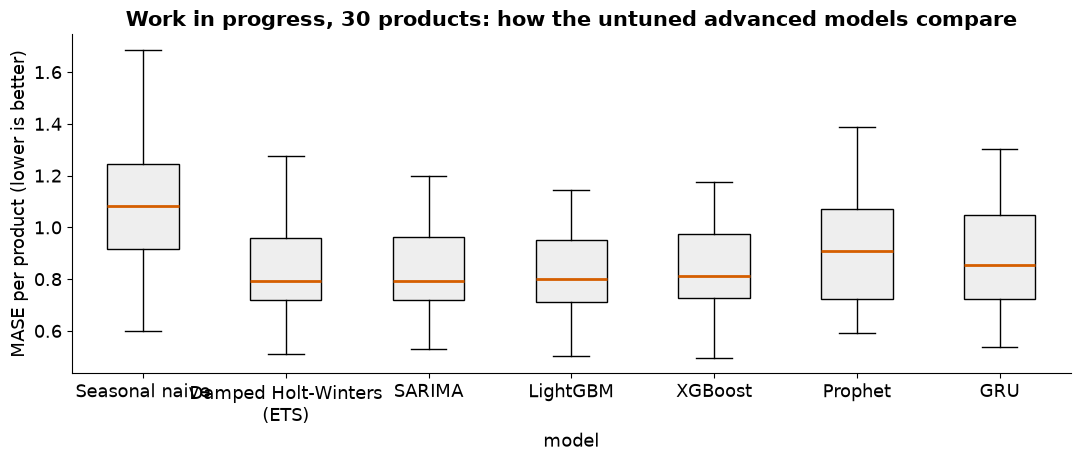

In [6]:
wide = per_item.pivot(index="item_id", columns="model", values="mase")[order]
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.boxplot([wide[x].dropna() for x in order], showfliers=False, patch_artist=True,
           boxprops=dict(facecolor="#EEEEEE"), medianprops=dict(color="#D55E00", lw=2))
labels = {**NAMES, "xgboost": "XGBoost", "prophet": "Prophet", "gru": "GRU"}
ax.set_xticks(range(1, len(order) + 1), [labels[x].replace(" (ETS)", "\n(ETS)") for x in order])
ax.set_xlabel("model")
ax.set_ylabel("MASE per product (lower is better)")
ax.set_title("Work in progress, 30 products: how the untuned advanced models compare")
fig.tight_layout()
fig.savefig(FIGS / "advanced_wip_mase.png")
written.append(FIGS / "advanced_wip_mase.png")
plt.show()

## What we found so far

On these 30 products none of the three new models beats what we already have, untuned as they are. The median MASE
is 0.794 for ETS and SARIMA, 0.799 for LightGBM, 0.813 for XGBoost, 0.854 for the GRU and 0.908 for Prophet, against
1.082 for seasonal naive. These 30 are harder than the 150-product sample as a whole, which is why every number is
higher than in 10.

XGBoost on the same features lands close to LightGBM, as you would expect from two boosted-tree models; it beats
LightGBM on 30% of the products. The GRU beats seasonal naive on all 30 products but LightGBM on only 23%, which is
not bad for a network that sees nothing but the last 56 days of one product's sales. Prophet is the weakest of the
three and beats seasonal naive on only 77% of products; with default settings it also warned that two years of
history is the minimum for its yearly term.

Thirty products and no tuning are not enough to rank these models, so none of this goes into the findings. What it
does show is that the code runs end to end on the same backtest, and that none of the three is an easy win.


## What comes next

A proper run would need all 150 products (or all 726 for XGBoost), some tuning on a validation origin before the
scored ones, Prophet with the SNAP and event regressors it can take, and a GRU with more context (price, calendar)
and more data. Until then these numbers are only a sign of whether that is worth doing.

In [7]:
# files this notebook wrote
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

data\processed\advanced_xgboost_forecasts.parquet 39 KB
data\processed\advanced_prophet_forecasts.parquet 62 KB
data\processed\advanced_gru_forecasts.parquet 62 KB
outputs\tables\advanced_wip_summary.csv 1 KB
outputs\tables\advanced_wip_item_scores.csv 29 KB
outputs\figures\advanced_wip_mase.png 56 KB
